# PV Isotherms for Water

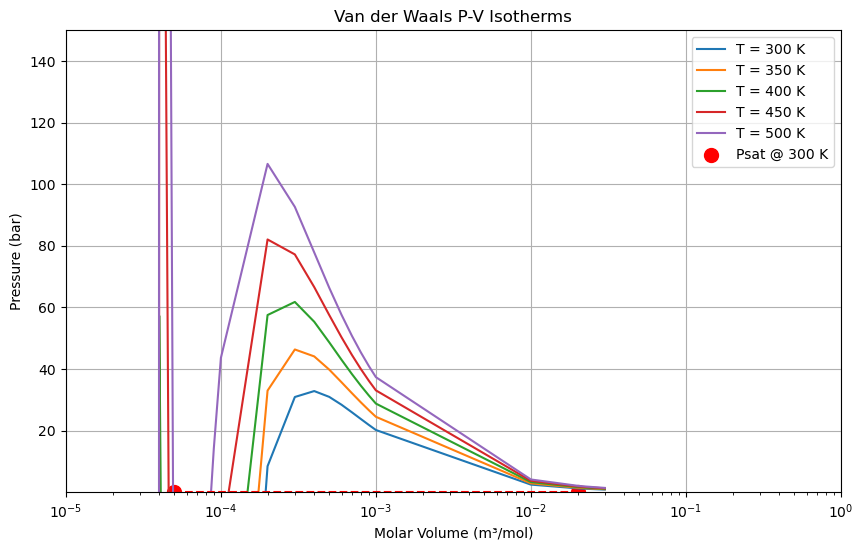

In [19]:
import matplotlib.pyplot as plt

# Constants
Tc = 647.15  # K
Pc = 220 * 10**5  # Pa
R = 8.314  # J/mol·K

# Temperatures to plot isotherms for
T = [300, 350, 400, 450, 500]

# Van der Waals constants
a = (27 * R**2 * Tc**2) / (64 * Pc)
b = (R * Tc) / (8 * Pc)

# Molar volumes (in m³/kmol = m³ per 1000 mol)
V_m3perkmol = [4e-05, 4.2e-05, 4.3e-05, 4.4e-05, 4.5e-05, 4.6e-05, 4.7e-05, 4.8e-05, 4.9e-05, 5e-05, 6e-05, 7e-05, 8e-05, 9e-05, 1e-04, 1e-03, 
               2e-03, 3e-03, 4e-03, 5e-03, 6e-03, 7e-03, 8e-03, 9e-03, 0.01, 0.02, 0.03, 0.04,0.05, 0.06, 0.07, 0.07, 0.08, 0.09, 0.1, 0.2,
               0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.8, 0.9, 1, 10, 20, 22.4, 22.7, 30]

# Convert to m³/mol for use with R (J/mol·K)
V = [v / 1000 for v in V_m3perkmol]

# Plotting
plt.figure(figsize=(10, 6))

for t in T:
    P = []
    for v in V:
        try:
            p = ((R * t) / (v - b)) - (a / v**2)
            P.append(p / 1e5)  # Convert from Pa to bar
        except ZeroDivisionError:
            P.append(float('inf'))  # Avoid division by zero
    plt.plot(V, P, label=f'T = {t} K')

psat_300K = 0.035  # bar (replace with actual value)
v_liq = 0.00005    # m³/mol (estimated saturated liquid volume)
v_vap = 0.02       # m³/mol (estimated saturated vapor volume)

# Plot points at Psat
plt.scatter([v_liq, v_vap], [psat_300K, psat_300K],
            color='red', marker='o', s=100,
            label='Psat @ 300 K')

# Horizontal line to connect saturated liquid and vapor volumes
plt.hlines(psat_300K, v_liq, v_vap, colors='red', linestyles='dashed')

# Plot settings
plt.xlabel('Molar Volume (m³/mol)')
plt.ylabel('Pressure (bar)')
plt.title('Van der Waals P-V Isotherms')
plt.legend()
plt.grid(True)
plt.xlim(0.00001,1)
plt.ylim(0.01, 150)  # adjust based on expected pressure range
plt.xscale('log')
# optional: log scale for better visibility at low V
plt.show()

